# Лабораторная работа № 1
## Вариант № 11

**Дисциплина:** «Методы анализа больших данных»  
**Профиль:** «Информатика и английский язык»  
**Среда:** Google Colab, Python 3.10+

| Поле | Значение |
|---|---|
| ФИО | Теркун Степан Анатольевич |
| Группа | ИНФА-231 |
| Вариант | 11 |
| Фильтр | `test preparation course == 'none'` |
| Метрики | Math, Reading, Writing |
| Метод | IQR; медиана |

### Постановка задачи

Беру учащихся, которые не проходили подготовительный курс (`test preparation course == "none"`), и сравниваю у них баллы по письму (`writing score`) у девушек и юношей

Сначала проверяю качество данных, заполняю пропуски (числовые медианой, категориальные модой) и убираю выбросы методом IQR. Потом сравниваю средние и проверяю гипотезу двусторонним Welch t-test при $\alpha=0.05$.

**Гипотеза.** EN: Among students without test preparation, writing scores differ between female and male students. RU: Среди не проходивших подготовку баллы по письму различаются у девушек и юношей

Дополнительно повторяю основные расчёты в **BigQuery** и сравниваю с `pandas`

## Блок 1. Импорт библиотек и прямая загрузка датасета

Основной URL берётся строго из условия лабораторной работы. Если он недоступен по сетевой или HTTP-причине, код автоматически обращается к резервному публичному URL на тот же `StudentsPerformance.csv`.

Ручная загрузка файла в Colab не используется.


In [1]:
import io
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

PRIMARY_URL = "https://raw.githubusercontent.com/sriharikadali/Students-Performance-in-Exams/master/StudentsPerformance.csv"
FALLBACK_URL = "https://raw.githubusercontent.com/NadavKiani/Students-Performance-in-Exams/master/StudentsPerformance.csv"


def load_students_performance(primary_url: str, fallback_url: str):
    """
    Загружает CSV непосредственно по HTTPS.
    Сначала используется URL из задания, затем резервный URL.
    """
    errors = []

    for url in (primary_url, fallback_url):
        try:
            with urllib.request.urlopen(url, timeout=30) as response:
                raw_bytes = response.read()

            dataframe = pd.read_csv(io.BytesIO(raw_bytes))

            required_columns = {
                "gender",
                "race/ethnicity",
                "parental level of education",
                "lunch",
                "test preparation course",
                "math score",
                "reading score",
                "writing score",
            }

            missing_columns = required_columns - set(dataframe.columns)
            if missing_columns:
                raise ValueError(
                    f"Отсутствуют обязательные столбцы: {sorted(missing_columns)}"
                )

            return dataframe, url

        except Exception as exc:
            errors.append(
                f"{url} -> {type(exc).__name__}: {exc}"
            )

    raise RuntimeError(
        "Не удалось загрузить датасет.\n" + "\n".join(errors)
    )


df_raw, USED_URL = load_students_performance(PRIMARY_URL, FALLBACK_URL)

print("Dataset loaded successfully / Датасет успешно загружен")
print("Used URL / Использованный URL:")
print(USED_URL)
print("Shape / Размер:", df_raw.shape)

display(df_raw.head())


Dataset loaded successfully / Датасет успешно загружен
Used URL / Использованный URL:
https://raw.githubusercontent.com/NadavKiani/Students-Performance-in-Exams/master/StudentsPerformance.csv
Shape / Размер: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### Короткое пояснение результата

Датасет загрузился, в нём **1000 строк и 8 столбцов**. Основная ссылка из задания сейчас не работает (ошибка 404), поэтому код сам взял резервную. Структура файла такая же, как в условии

## Блок 2. Первичная проверка и контроль качества

Проверяются:

- структура таблицы;
- типы данных;
- пропуски $NaN$;
- полные дубликаты;
- диапазон баллов 0–100;
- значения категориальных полей.

Доля пропусков:

$$
r_{miss}=\frac{N_{miss}}{N}.
$$


In [2]:
score_cols = ["math score", "reading score", "writing score"]

categorical_cols = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course",
]

print("Rows, columns / Строки, столбцы:", df_raw.shape)

print("\n--- INFO ---")
df_raw.info()

print("\n--- FIRST ROWS / ПЕРВЫЕ СТРОКИ ---")
display(df_raw.head())

missing_report = df_raw.isna().sum().to_frame("missing_count")
missing_report["missing_percent"] = (
    missing_report["missing_count"] / len(df_raw) * 100
)

print("\n--- MISSING VALUES / ПРОПУСКИ ---")
display(missing_report)

duplicate_count = int(df_raw.duplicated().sum())
print("Exact duplicates / Полные дубликаты:", duplicate_count)

print("\n--- NUMERIC DESCRIPTION / ЧИСЛОВАЯ СТАТИСТИКА ---")
display(df_raw[score_cols].describe().T)

range_check = pd.DataFrame({
    "below_0": (df_raw[score_cols] < 0).sum(),
    "above_100": (df_raw[score_cols] > 100).sum(),
})

print("\n--- RANGE CHECK 0..100 / ПРОВЕРКА ДИАПАЗОНА ---")
display(range_check)

for col in categorical_cols:
    print(f"\nColumn / Столбец: {col}")
    display(df_raw[col].value_counts(dropna=False).to_frame("count"))


Rows, columns / Строки, столбцы: (1000, 8)

--- INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

--- FIRST ROWS / ПЕРВЫЕ СТРОКИ ---


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75



--- MISSING VALUES / ПРОПУСКИ ---


,missing_count,missing_percent
gender,0,0.0
race/ethnicity,0,0.0
parental level of education,0,0.0
lunch,0,0.0
test preparation course,0,0.0
math score,0,0.0
reading score,0,0.0
writing score,0,0.0


Exact duplicates / Полные дубликаты: 0

--- NUMERIC DESCRIPTION / ЧИСЛОВАЯ СТАТИСТИКА ---


...

,count
parental level of education,
some college,226
associate's degree,222
high school,196
some high school,179
bachelor's degree,118
master's degree,59



Column / Столбец: lunch


,count
lunch,
standard,645
free/reduced,355



Column / Столбец: test preparation course


,count
test preparation course,
none,642
completed,358


### Короткое пояснение результата

Пропусков и полных дубликатов в данных нет. Все три балла лежат в диапазоне от 0 до 100. Исправлять пропуски не нужно, но код обработки я все равно оставил, как требуется в задании

### Обработка пропусков варианта № 11

Даже если исходный файл не содержит `NaN`, алгоритм обработки должен быть реализован полностью:

- числовые признаки → медиана;
- категориальные признаки → мода.

Исходный `df_raw` не изменяется.


In [3]:
df = df_raw.copy()

# Удаление полных дублей, если они есть.
n_before = len(df)
df = df.drop_duplicates().copy()
n_after = len(df)

print(
    "Removed exact duplicates / Удалено полных дублей:",
    n_before - n_after
)

# Медианная импутация числовых полей.
for col in score_cols:
    missing_before = int(df[col].isna().sum())
    median_value = df[col].median()

    df[col] = df[col].fillna(median_value)

    print(
        f"{col}: NaN before={missing_before}; "
        f"median={median_value:.2f}"
    )

# Импутация модой категориальных полей.
for col in categorical_cols:
    missing_before = int(df[col].isna().sum())

    if missing_before > 0:
        mode_series = df[col].mode(dropna=True)

        if mode_series.empty:
            raise ValueError(
                f"Невозможно определить моду для столбца {col}"
            )

        mode_value = mode_series.iloc[0]
        df[col] = df[col].fillna(mode_value)
    else:
        mode_value = "not required / не требуется"

    print(
        f"{col}: NaN before={missing_before}; "
        f"mode={mode_value}"
    )

print("\nNaN after imputation / Пропуски после импутации:")
display(df.isna().sum().to_frame("missing_count"))


Removed exact duplicates / Удалено полных дублей: 0
math score: NaN before=0; median=66.00
reading score: NaN before=0; median=70.00
writing score: NaN before=0; median=69.00
gender: NaN before=0; mode=not required / не требуется
race/ethnicity: NaN before=0; mode=not required / не требуется
parental level of education: NaN before=0; mode=not required / не требуется
lunch: NaN before=0; mode=not required / не требуется
test preparation course: NaN before=0; mode=not required / не требуется

NaN after imputation / Пропуски после импутации:


,missing_count
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


### Короткое пояснение результата

Таблица после импутации не изменилась, тк пропусков было 0 во всех столбцах. Медианы посчитались, но подставлять их никуда не пришлось

## Блок 3. Поиск и обработка выбросов методом IQR

Для каждого экзаменационного показателя:

$$
IQR=Q_3-Q_1,
$$

$$
L=Q_1-1.5\cdot IQR,
$$

$$
U=Q_3+1.5\cdot IQR.
$$

Строка исключается в учебном решении, если хотя бы один из трёх баллов находится вне своего IQR-интервала.

В реальном образовательном исследовании такие наблюдения сначала должны проходить предметную проверку: низкий или высокий балл может быть редким, но корректным результатом.


In [4]:
iqr_bounds = {}
outlier_mask = pd.Series(False, index=df.index)

for col in score_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    iqr_bounds[col] = {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower": lower,
        "upper": upper,
    }

    current_outliers = (
        (df[col] < lower) |
        (df[col] > upper)
    )

    outlier_mask = outlier_mask | current_outliers

bounds_df = pd.DataFrame(iqr_bounds).T

bounds_df["outlier_count"] = [
    int(
        (
            (df[col] < bounds_df.loc[col, "lower"]) |
            (df[col] > bounds_df.loc[col, "upper"])
        ).sum()
    )
    for col in score_cols
]

display(bounds_df.round(3))

print(
    "Rows with >=1 IQR outlier / "
    "Строк с хотя бы одним IQR-выбросом:",
    int(outlier_mask.sum())
)

df_clean = df.loc[~outlier_mask].copy()

print("Rows before / Строк до очистки:", len(df))
print("Rows after / Строк после очистки:", len(df_clean))
print("Removed / Удалено:", len(df) - len(df_clean))

display(df_clean.head())


,Q1,Q3,IQR,lower,upper,outlier_count
math score,57.00,77.0,20.00,27.000,107.000,8
reading score,59.00,79.0,20.00,29.000,109.000,6
writing score,57.75,79.0,21.25,25.875,110.875,5


Rows with >=1 IQR outlier / Строк с хотя бы одним IQR-выбросом: 12
Rows before / Строк до очистки: 1000
Rows after / Строк после очистки: 988
Removed / Удалено: 12


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### Короткое пояснение результата

По IQR нашлось **12 строк**, где хотя бы один балл выходит за границы (по математике 8, по чтению 6, по письму 5, некоторые строки совпадают). После очистки осталось **988 строк**

Сразу считать такие баллы ошибкой нельзя, это может быть просто редкий, но настоящий результат. В учебной работе я их убираю, а в реальном исследовании их надо сначала проверить

### Дополнительная демонстрация Min-Max нормализации

Исходные баллы сохраняются, а нормализованные значения создаются в новых столбцах:

$$
x_{norm}=\frac{x-x_{min}}{x_{max}-x_{min}}.
$$


In [5]:
df_normalized = df_clean.copy()

for col in score_cols:
    x_min = df_clean[col].min()
    x_max = df_clean[col].max()

    if x_max == x_min:
        df_normalized[col + "_norm"] = 0.0
    else:
        df_normalized[col + "_norm"] = (
            (df_clean[col] - x_min) /
            (x_max - x_min)
        )

norm_cols = [col + "_norm" for col in score_cols]
display(df_normalized[norm_cols].describe().T)


,count,mean,std,min,25%,50%,75%,max
math score_norm,988.0,0.542815,0.197389,0.0,0.410959,0.534247,0.684932,1.0
reading score_norm,988.0,0.572404,0.197419,0.0,0.436620,0.577465,0.718310,1.0
writing score_norm,988.0,0.569408,0.198976,0.0,0.424658,0.575342,0.712329,1.0


### Короткое пояснение результата

После Min-Max нормализации все баллы лежат от 0 до 1. Нормализованные столбцы тут просто для примера, гипотезу я проверяю по обычным баллам

### Фильтрация варианта № 11

Оставляю учащихся с `test preparation course == "none"`. Дальше сравниваю девушек (`female`) и юношей (`male`)


In [6]:
df_v11 = df_clean.loc[
    df_clean["test preparation course"].eq("none")
].copy()

group_counts = (
    df_v11["gender"]
    .value_counts()
    .rename_axis("gender")
    .to_frame("n")
)

print(
    "Variant 11 sample / Выборка варианта №11:",
    df_v11.shape
)

display(group_counts)

group_stats = (
    df_v11
    .groupby("gender")[score_cols]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

display(group_stats.round(2))

display(df_v11.groupby("gender")["writing score"].describe().round(2))


Variant 11 sample / Выборка варианта №11: (631, 8)


,n
gender,
female,327
male,304


math score                               reading score                               writing score         \
            count   mean median    std min  max         count   mean median    std min  max         count   mean   
gender                                                                                                             
female        327  62.63   63.0  14.48  27  100           327  70.81   71.0  13.54  29  100           327  69.87   
male          304  67.16   67.5  13.51  27   97           304  63.29   63.0  12.74  29   96           304  60.16   

                               
       median    std min  max  
gender                         
female   70.0  13.81  30  100  
male     60.0  12.71  27   92

,count,mean,std,min,25%,50%,75%,max
gender,,,,,,,,
female,327.0,69.87,13.81,30.0,61.0,70.0,79.50,100.0
male,304.0,60.16,12.71,27.0,51.0,60.0,69.25,92.0


### Короткое пояснение результата

После фильтра осталось **631 учащийся**, из них девушек **327**, юношей **304**

Средний балл по письму у девушек **69,87**, у юношей **60,16**, разница примерно **9,71 балла**. Медианы 70 и 60, у девушек Q1 = 61 и Q3 = 79,5, у юношей Q1 = 51 и Q3 = 69,25. По чтению девушки тоже выше (70,81 против 63,29), а по математике наоборот выше юноши (67,16 против 62,63). Дальше проверю, значима ли разница по письму

## Блок 4. Визуализация

Строятся три обязательных графика:

1. Boxplot.
2. Histplot.
3. Correlation Heatmap.

Подписи выполняются на английском и русском языках.


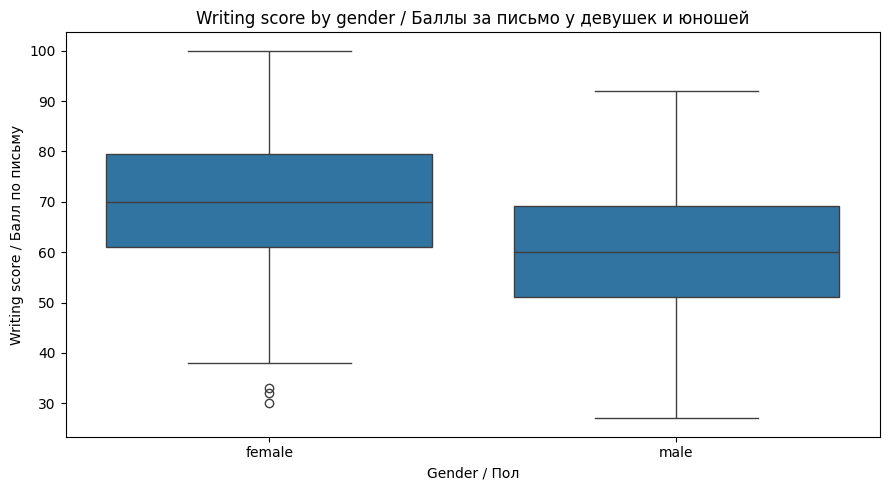

In [7]:
# 1. BOXPLOT
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_v11,
    x="gender",
    y="writing score"
)

plt.title(
    "Writing score by gender / "
    "Баллы за письмо у девушек и юношей"
)
plt.xlabel(
    "Gender / Пол"
)
plt.ylabel(
    "Writing score / Балл по письму"
)

plt.tight_layout()
plt.show()


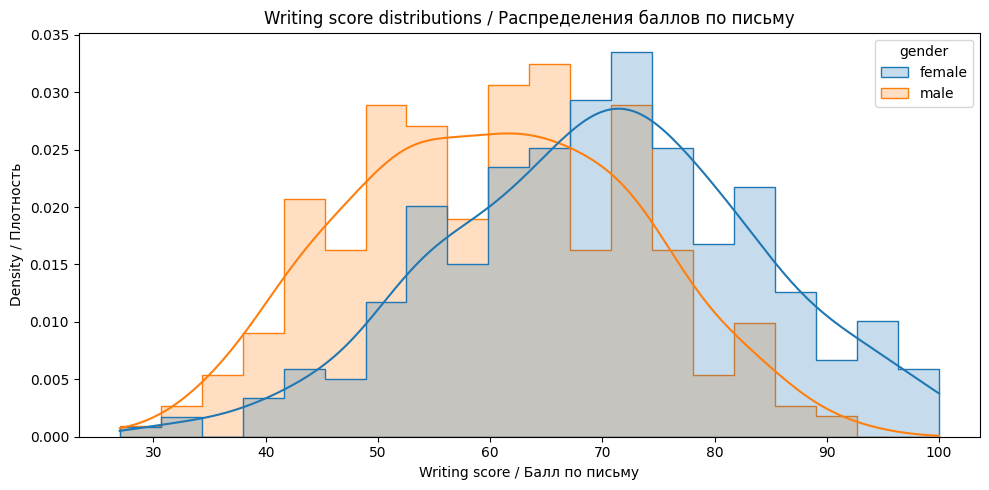

In [8]:
# 2. HISTPLOT
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_v11,
    x="writing score",
    hue="gender",
    bins=20,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title(
    "Writing score distributions / "
    "Распределения баллов по письму"
)
plt.xlabel("Writing score / Балл по письму")
plt.ylabel("Density / Плотность")

plt.tight_layout()
plt.show()


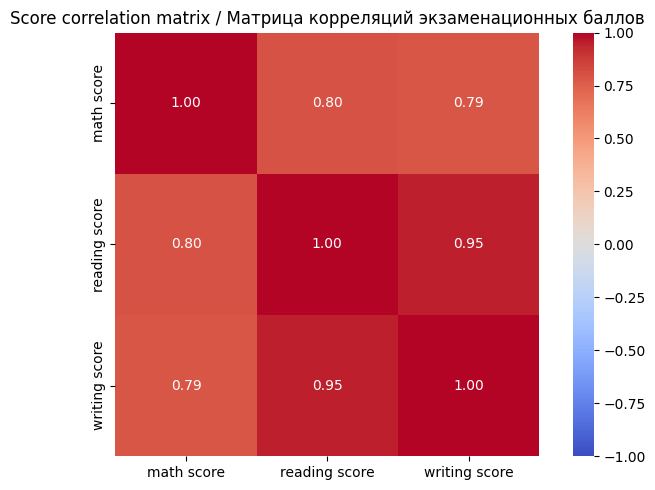

,math score,reading score,writing score
math score,1.000,0.798,0.789
reading score,0.798,1.000,0.952
writing score,0.789,0.952,1.000


In [9]:
# 3. CORRELATION HEATMAP
corr_matrix = df_v11[score_cols].corr(method="pearson")

plt.figure(figsize=(7, 5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    square=True,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.title(
    "Score correlation matrix / "
    "Матрица корреляций экзаменационных баллов"
)

plt.tight_layout()
plt.show()

display(corr_matrix.round(3))


### Короткое пояснение результата

На boxplot и гистограмме видно, что у девушек баллы по письму в целом выше, распределение сдвинуто вправо. В корреляционной матрице сильнее всего связаны `reading score` и `writing score`, **r ≈ 0,952**. С математикой связь чуть слабее (0,789 с письмом и 0,798 с чтением)

Корреляция показывает только то, что баллы меняются вместе, причину она не доказывает

## Блок 5. Проверка гипотезы варианта № 11

В задании сказано что баллы «различаются», без направления, поэтому беру двусторонний Welch t-test для двух независимых групп

$$
H_0:\ \mu_{female}=\mu_{male}
$$

$$
H_1:\ \mu_{female}\neq\mu_{male}
$$

$$
\alpha=0.05.
$$

Если $p<0.05$, отклоняем $H_0$. Если $p\geq0.05$, оснований говорить о различии нет


In [10]:
female = df_v11.loc[
    df_v11["gender"].eq("female"),
    "writing score"
].astype(float)

male = df_v11.loc[
    df_v11["gender"].eq("male"),
    "writing score"
].astype(float)

print("female: n =", len(female))
print("male:   n =", len(male))
print(f"female mean = {female.mean():.3f}")
print(f"male mean   = {male.mean():.3f}")
print(
    f"mean difference = "
    f"{female.mean() - male.mean():.3f}"
)

result = stats.ttest_ind(
    female,
    male,
    equal_var=False
)

t_stat = float(result.statistic)
p_value = float(result.pvalue)

alpha = 0.05

print("\nWelch two-sided t-test")
print(f"t = {t_stat:.4f}")
print(f"p = {p_value:.8g}")
print(f"alpha = {alpha}")


female: n = 327
male:   n = 304
female mean = 69.875
male mean   = 60.161
mean difference = 9.713

Welch two-sided t-test
t = 9.1998
p = 5.2192199e-19
alpha = 0.05


### Короткое пояснение результата

Для `writing score` получилось:

- среднее у девушек **69,87**;
- среднее у юношей **60,16**;
- разница **9,71 балла**;
- $t=9{,}20$;
- $p\approx5{,}2\cdot10^{-19}$.

$p$ намного меньше 0,05, поэтому $H_0$ отклоняем. В этой выборке баллы по письму у девушек и юношей, не проходивших подготовку, различаются, у девушек они выше. Но почему так получилось, тест не говорит

### Размер эффекта

Статистическая значимость не показывает величину различия. Поэтому дополнительно вычисляется Cohen's $d$:

$$
d=\frac{\bar{x}_1-\bar{x}_2}{s_p},
$$

где $s_p$ — объединённое стандартное отклонение.


In [11]:
def cohens_d_independent(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    nx = len(x)
    ny = len(y)

    sx2 = np.var(x, ddof=1)
    sy2 = np.var(y, ddof=1)

    pooled_sd = np.sqrt(
        ((nx - 1) * sx2 + (ny - 1) * sy2) /
        (nx + ny - 2)
    )

    if pooled_sd == 0:
        return 0.0

    return (
        np.mean(x) - np.mean(y)
    ) / pooled_sd


d = cohens_d_independent(female, male)

if abs(d) < 0.2:
    magnitude = "very small / очень малый"
elif abs(d) < 0.5:
    magnitude = "small / малый"
elif abs(d) < 0.8:
    magnitude = "medium / средний"
else:
    magnitude = "large / большой"

print(f"Cohen's d = {d:.3f}")
print(
    "Effect magnitude / Размер эффекта:",
    magnitude
)


Cohen's d = 0.731
Effect magnitude / Размер эффекта: medium / средний


### Короткое пояснение результата

Получилось **Cohen's d = 0,731**, по учебной шкале это **средний эффект** (почти большой). То есть разница не только значимая, но и заметная по размеру


### Автоматическая формулировка вывода

Код ниже печатает статистический вывод и отдельно педагогический. Разделяю их специально, тк связь в данных не доказывает причину


In [12]:
mean_female = female.mean()
mean_male = male.mean()
difference = mean_female - mean_male

print("=" * 78)
print("STATISTICAL CONCLUSION / СТАТИСТИЧЕСКИЙ ВЫВОД")
print("=" * 78)

if p_value < alpha:
    print(
        f"p={p_value:.8g} < {alpha}. "
        "H0 отклоняется в пользу H1."
    )
    print(
        f"Средний writing score: female="
        f"{mean_female:.2f}; male={mean_male:.2f}."
    )
    print(
        f"Разница средних = {difference:.2f} балла."
    )
else:
    print(
        f"p={p_value:.8g}. "
        "Недостаточно оснований говорить о различии."
    )

print("\n" + "=" * 78)
print("PEDAGOGICAL INTERPRETATION / ПЕДАГОГИЧЕСКИЙ ВЫВОД")
print("=" * 78)

print(
    "В этой выборке среди не проходивших подготовку баллы по письму "
    "у девушек и юношей различаются."
)

print(
    "Нельзя говорить, что пол сам по себе причина разницы, и тем более "
    "делать выводы о способностях конкретного ученика: на результат могут "
    "влиять интерес к чтению и письму, привычки, мотивация и другие факторы."
)

print(
    "Для урока корректно сказать 'в этой выборке группы различаются', "
    "а не 'девушки всегда пишут лучше'."
)


STATISTICAL CONCLUSION / СТАТИСТИЧЕСКИЙ ВЫВОД
p=5.2192199e-19 < 0.05. H0 отклоняется в пользу H1.
Средний writing score: female=69.87; male=60.16.
Разница средних = 9.71 балла.

PEDAGOGICAL INTERPRETATION / ПЕДАГОГИЧЕСКИЙ ВЫВОД
В этой выборке среди не проходивших подготовку баллы по письму у девушек и юношей различаются.
Нельзя говорить, что пол сам по себе причина разницы, и тем более делать выводы о способностях конкретного ученика: на результат могут влиять интерес к чтению и письму, привычки, мотивация и другие факторы.
Для урока корректно сказать 'в этой выборке группы различаются', а не 'девушки всегда пишут лучше'.


### Итог варианта № 11

Среди учащихся без подготовительного курса девушки в среднем получили по письму на **9,71 балла** больше, чем юноши. Разница статистически значима ($p<0.05$), размер эффекта средний (d ≈ 0,73)

Это наблюдательные данные, поэтому можно говорить только о различии групп в этой выборке. Сказать, что разницу вызывает именно пол, или делать по этому выводы о конкретном ученике нельзя

## Дополнительное задание. Повторение расчётов в BigQuery

Цель дополнительного задания — убедиться, что ключевые агрегаты можно получить не только в `pandas`, но и средствами GoogleSQL.

Чтобы результаты совпадали с Colab, в BigQuery загружается **уже очищенная таблица `df_clean`**.

In [13]:
# Подготовка CSV с удобными для BigQuery именами столбцов.
bq_export = df_clean.rename(columns={
    "race/ethnicity": "race_ethnicity",
    "parental level of education": "parental_education",
    "test preparation course": "test_preparation",
    "math score": "math_score",
    "reading score": "reading_score",
    "writing score": "writing_score",
}).copy()

BQ_CSV = "students_performance_lab01_clean.csv"
bq_export.to_csv(BQ_CSV, index=False)

print("Файл для BigQuery:", BQ_CSV)
print("Строк:", len(bq_export))
print("Столбцов:", len(bq_export.columns))

from google.colab import files
files.download(BQ_CSV)


Файл для BigQuery: students_performance_lab01_clean.csv
Строк: 988
Столбцов: 8


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Загрузка в BigQuery

1. Открыть `https://console.cloud.google.com/bigquery`.
2. Проект `edu-analytics-sandbox-511513`, датасет `learning_analytics` (уже есть с практической № 1).
3. ⋮ у датасета → **Create table**.
4. Файл `students_performance_lab01_clean.csv` (скачался из ячейки выше).
5. **File format:** `CSV`.
6. **Table:** `students_performance`.
7. **Schema → Auto detect**.
8. **Advanced options → Header rows to skip = 1**.
9. Проверить **Schema** и **Preview**.

### SQL 1. Контроль числа строк

```sql
SELECT
  COUNT(*) AS rows_count
FROM `edu-analytics-sandbox-511513.learning_analytics.students_performance`;
```

**Результат:** `988`, как и в Colab, значит загружена та же очищенная таблица

### SQL 2. Основные показатели варианта № 11

```sql
SELECT
  gender,
  COUNT(*) AS n,
  ROUND(AVG(math_score), 2) AS mean_math,
  ROUND(AVG(reading_score), 2) AS mean_reading,
  ROUND(AVG(writing_score), 2) AS mean_writing,
  MIN(writing_score) AS min_writing,
  MAX(writing_score) AS max_writing
FROM `edu-analytics-sandbox-511513.learning_analytics.students_performance`
WHERE test_preparation = 'none'
GROUP BY gender
ORDER BY gender;
```

**Результат:**

| gender | n | mean_math | mean_reading | mean_writing | min_writing | max_writing |
|---|---:|---:|---:|---:|---:|---:|
| `female` | 327 | 62.63 | 70.81 | 69.87 | 30 | 100 |
| `male` | 304 | 67.16 | 63.29 | 60.16 | 27 | 92 |

Все числа совпали с тем, что получилось в `pandas`

### SQL 3. Разница средних по письму

```sql
SELECT
  ROUND(
    AVG(IF(gender = 'female', writing_score, NULL))
    -
    AVG(IF(gender = 'male', writing_score, NULL)),
    2
  ) AS writing_mean_difference
FROM `edu-analytics-sandbox-511513.learning_analytics.students_performance`
WHERE test_preparation = 'none';
```

**Результат:** 9,71 балла, так же как в Colab

### SQL 4. Корреляции экзаменационных результатов

```sql
SELECT
  ROUND(CORR(math_score, reading_score), 3) AS corr_math_reading,
  ROUND(CORR(math_score, writing_score), 3) AS corr_math_writing,
  ROUND(CORR(reading_score, writing_score), 3) AS corr_reading_writing
FROM `edu-analytics-sandbox-511513.learning_analytics.students_performance`
WHERE test_preparation = 'none';
```

**Результат:** 0,798, 0,789 и 0,952, совпадает с heatmap в Colab

> Welch t-test делаю только в Colab, в BigQuery повторяю описательные расчеты

### Сравнение BigQuery и Colab

Результаты BigQuery полностью совпали с Colab: 988 строк, те же размеры групп (327 и 304), те же средние и корреляции. Значит в обеих средах одни и те же данные и одинаковый фильтр

## Методический блок. Технологическая карта фрагмента урока

| Элемент | Содержание |
|---|---|
| Тема | «Категориальные признаки и группировка» |
| Класс | 10–11 |
| Продолжительность | 20 минут |
| Тип занятия | Интегрированное «Информатика + английский язык» |
| Цель | Научиться делить таблицу на группы по категориальному признаку и сравнивать группы |
| Предметный результат | Ученик умеет отфильтровать данные, сгруппировать их через `groupby` и построить boxplot |
| Метапредметный результат | Ученик подкрепляет вывод данными и отличает различие групп от причины |
| Англоязычная составляющая | `category`, `group`, `mean`, `median`, `distribution`, `evidence` |
| Исходные данные | Обезличенный фрагмент `StudentsPerformance.csv` |
| Проблемный вопрос | Если у одной группы средний балл выше, значит ли это, что каждый из этой группы пишет лучше? |
| Действия учителя | Показывает таблицу, объясняет, что такое категориальный признак, показывает `groupby`, ведет обсуждение |
| Действия обучающихся | Фильтруют `test preparation course == 'none'`, группируют по `gender`, считают средние, строят boxplot, пишут вывод |
| Цифровые средства | Google Colab / Python (pandas, seaborn) |
| Контроль | 1) Какой признак здесь категориальный? 2) Чем среднее отличается от медианы на boxplot? 3) Что можно и что нельзя сказать по графику? |
| Рефлексия | «Что данные позволяют утверждать, а что нет?» |

**Ход фрагмента.** Проблемный вопрос (2 мин), загрузка данных (3 мин), фильтр и группировка (5 мин), boxplot (5 мин), обсуждение и вывод на русском и английском (5 мин)

**Дидактическое задание.** Отфильтруйте учащихся без подготовительного курса, сгруппируйте их по `gender` и сравните средние баллы по письму. Постройте boxplot. Сформулируйте вывод на русском и на английском со словами `group`, `higher`, `evidence`

Корректная фраза:

> `In this sample, female students without test preparation have higher writing scores on average.`

Некорректная:

> `Girls always write better than boys.`

**Методический вывод.** На таком задании школьники учатся работать с категориальными признаками и группировкой, а заодно видят, что разница средних между группами ничего не говорит о конкретном человеке. Тема с полом чувствительная, поэтому на уроке важно отдельно обсудить, почему такие данные нельзя использовать для ярлыков


---
## Оценивание лабораторной работы — 10 баллов

| Критерий | Баллы |
|---|---:|
| Загрузка, проверка и очистка данных в Colab | **2** |
| Индивидуальный анализ и описательная статистика | **2** |
| Визуализации | **1** |
| Проверка гипотезы и корректный статистический вывод | **2** |
| Дополнительные расчёты в BigQuery и сопоставление с Colab | **2** |
| Методический блок и оформление notebook | **1** |
| **Итого** | **10** |

# Приложения (скриншоты из BigQuery)

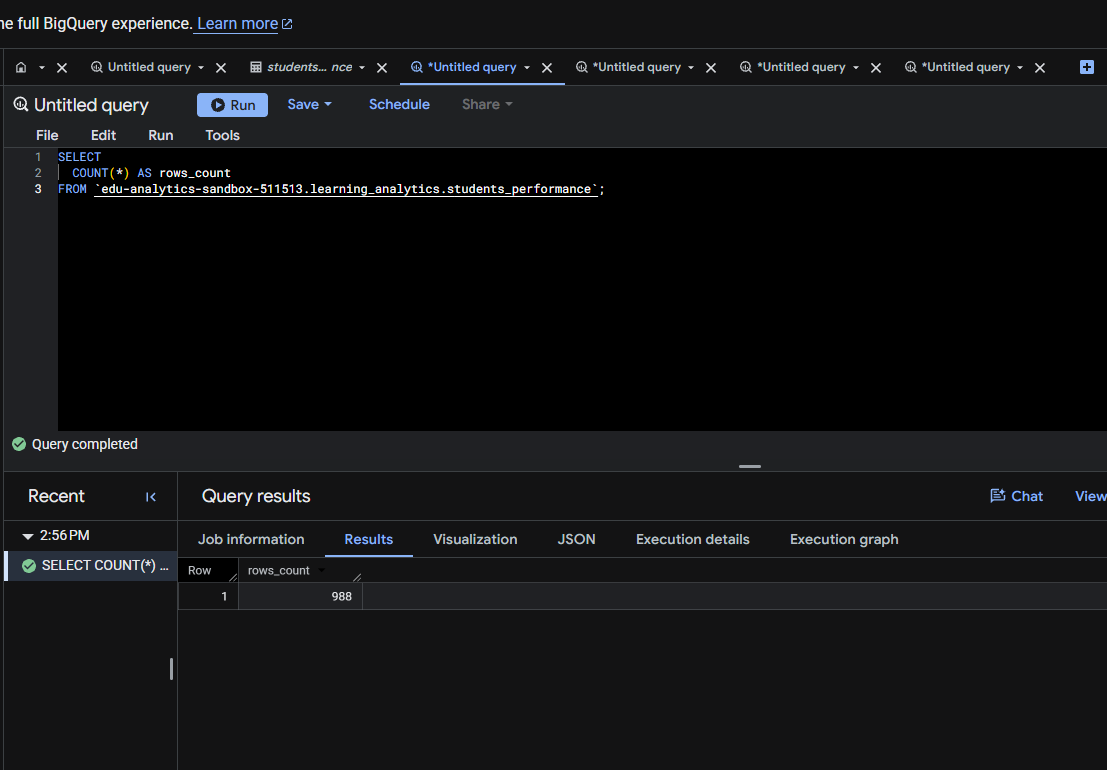

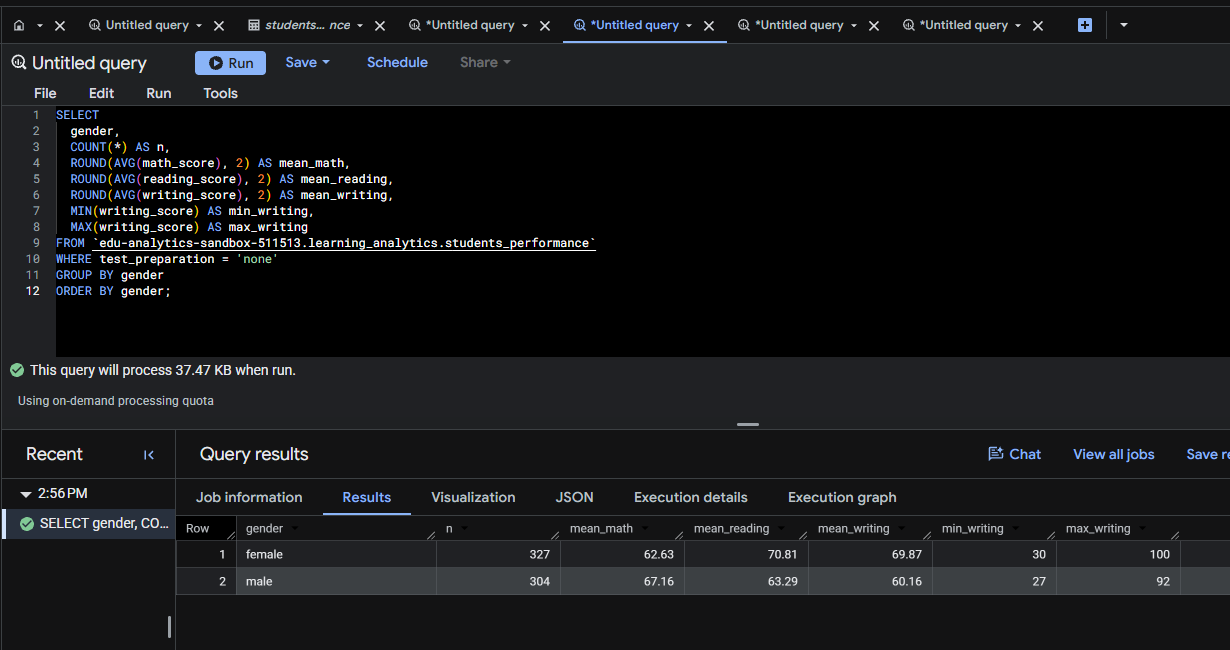

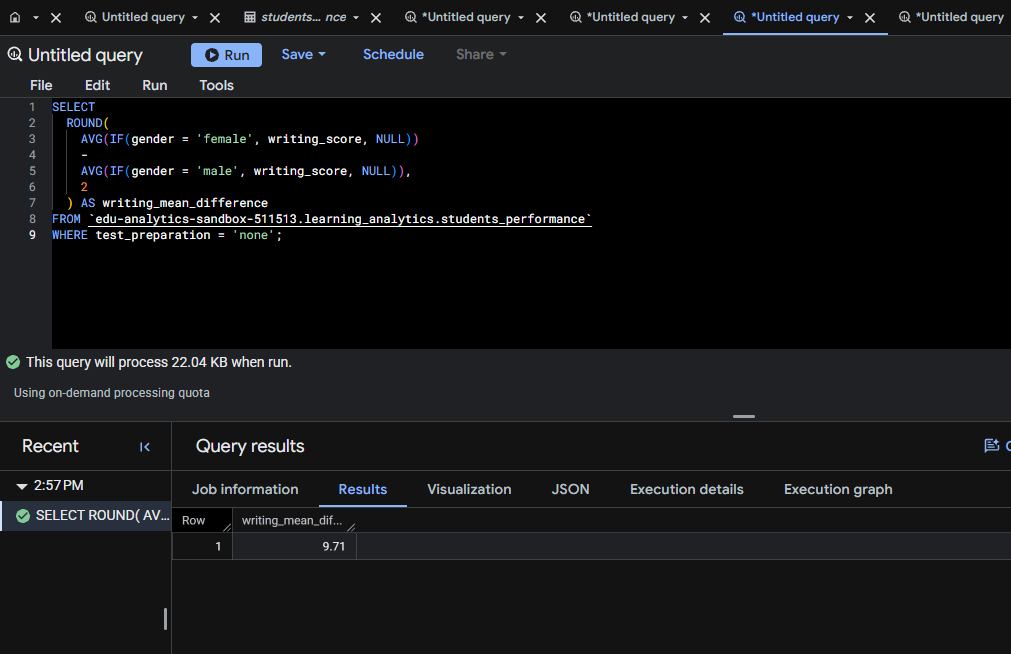

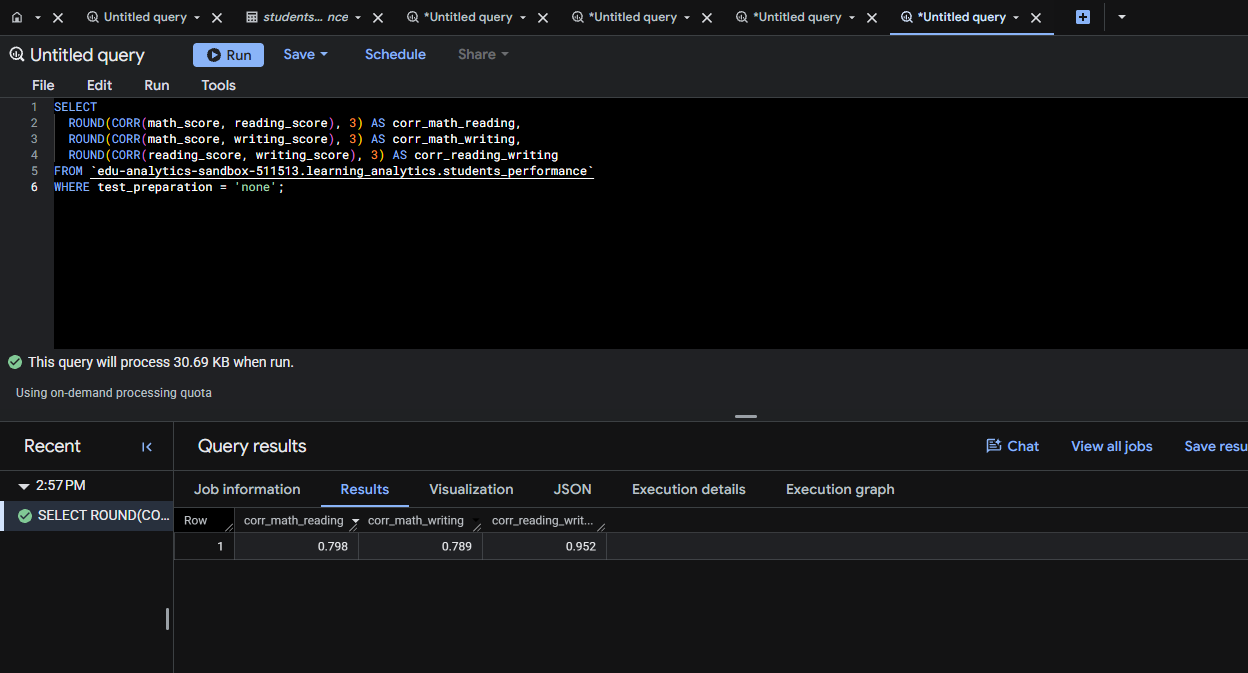

Все значения совпали